# 2.3 Shear: members without and with links, punching

EC2 6.2 and 6.4.

In [1]:
import sys; sys.path.insert(0, '..')
from ec2.setup import *

## Members without shear reinforcement (EC2 6.2.2)

$$V_{Rd,c} = \max\left\{C_{Rd,c}\,k\,(100\rho_l f_{ck})^{1/3};\; v_{min}\right\} b_w d, \quad C_{Rd,c} = \frac{0.18}{\gamma_c}, \quad k = 1+\sqrt{\frac{200}{d}}\le 2, \quad v_{min} = 0.035k^{3/2}f_{ck}^{1/2}$$

Solid slabs need no links when $V_{Ed}\le V_{Rd,c}$. Beams still need minimum links (EC2 6.2.1(4)).

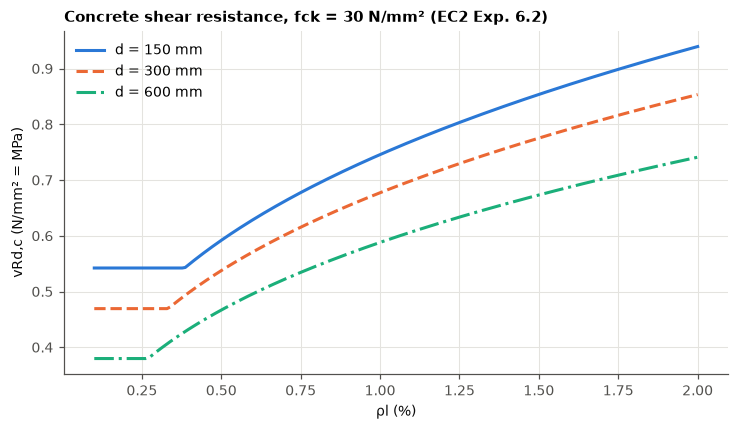

In [2]:
P.shear_chart(30)

## Members with links: variable strut inclination (EC2 6.2.3)

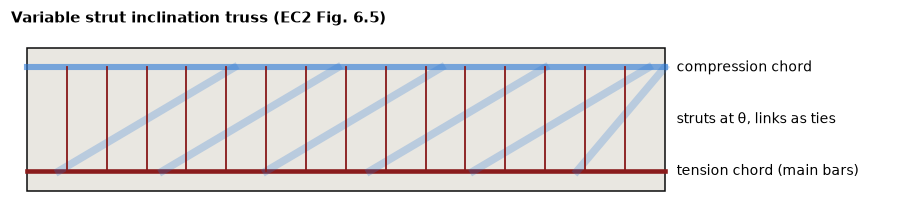

In [3]:
P.sketch_truss()

$$V_{Rd,s} = \frac{A_{sw}}{s}\,z f_{ywd}\cot\theta, \qquad V_{Rd,max} = \frac{\alpha_{cw}b_w z\nu_1 f_{cd}}{\cot\theta+\tan\theta}, \qquad 1\le\cot\theta\le2.5$$

with $z = 0.9d$, $\alpha_{cw}=1$, $\nu_1 = 0.6(1-f_{ck}/250)$.

Because $\cot\theta+\tan\theta = 2/\sin2\theta$, setting $V_{Rd,max}=V_{Ed}$ gives the flattest permissible strut:

$$\theta = \tfrac12\sin^{-1}\left(\frac{V_{Ed}}{V_{Rd,max}(\theta=45^\circ)}\right)$$

**Procedure.** (1) Check the strut at the face of the support. (2) Find cot θ, limited to 1 to 2.5. (3) Design links for the shear at d from the face (EC2 6.2.1(8)).
(4) Check minimum links $A_{sw}/(s\,b_w)\ge 0.08\sqrt{f_{ck}}/f_{yk}$, longitudinal spacing ≤ 0.75d, transverse spacing ≤ min(0.75d, 600 mm).
(5) Add the longitudinal tension $\Delta F_{td}=0.5V_{Ed}\cot\theta$, or shift the moment diagram by $a_l = z\cot\theta/2$.

### Input guide

| Name | Meaning | Unit | Expected |
|:--|:--|:--|:--|
| `V_face` | Design shear at the face of the support | kN | > 0 |
| `V_d` | Design shear at d from the face | kN | ≤ V_face |
| `bw`, `d` | Web width, effective depth | mm |  |
| `As` | Anchored tension steel | mm² |  |
| `fck`, `fyk` | Concrete and steel strength | N/mm² | 12 to 50; 400 to 600 |
| `link`, `legs`, `spacing` | Link size, number of legs, spacing to verify | mm | 8, 10, 12, 16, 20, 25, 32 |

In [4]:
# INPUTS: edit only this cell, then run the cells below it
V_ = dict(V_face=260, V_d=230, bw=300, d=450, As=942, fck=30, fyk=500,      # kN, mm, mm², N/mm²
          link=8, legs=2, spacing=150)                                     # links to verify

In [5]:
s = Sheet("Beam shear", element=f"{V_['bw']} mm wide, V = {V_['V_face']} kN")
D.materials(s, V_["fck"], V_["fyk"], BRIEF["ndp"], show=False); s.rows = []
D.shear_beam(s, V_["V_face"], V_["V_d"], V_["bw"], V_["d"], V_["As"], V_["link"], V_["legs"], V_["spacing"]); s.show("Shear design"); s.summary()

## Beam shear

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* 300 mm wide, V = 260 kN

### Shear design

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Shear at face of support: $V_{Ed,face}$ | $V_{Ed,face} = 260$ kN |
| EC2 6.2.1(8) | Shear at d from face: $V_{Ed,d}$ | $V_{Ed,d} = 230$ kN |
|  | $b_{w}$ | $b_{w} = 300$ mm |
|  | $d$ | $d = 450$ mm |
| EC2 Fig. 6.3 | Anchored tension steel: $A_{sl}$ | $A_{sl} = 942$ mm² |
| EC2 6.2.2(1), NA | $C_{Rd,c} = \dfrac{0.18}{\gamma_{c}}$<br>$\quad = \dfrac{0.18}{1.5}$ | $\mathbf{C_{Rd,c} = 0.12}$ |
| EC2 6.2.2(1) | $k = \min\left\{1 + \sqrt{\dfrac{200}{d}};\; 2\right\}$<br>$\quad = \min\left\{1 + \sqrt{\dfrac{200}{450}};\; 2\right\}$ | $\mathbf{k = 1.667}$ |
| EC2 6.2.2(1) | $\rho_{l} = \min\left\{\dfrac{A_{sl}}{b_{w}\,d};\; 0.02\right\}$<br>$\quad = \min\left\{\dfrac{942}{300\times 450};\; 0.02\right\}$ | $\mathbf{\rho_{l} = 0.00698}$ |
| EC2 Exp. (6.3N) | $v_{min} = 0.035\,k^{1.5}\,\sqrt{f_{ck}}$<br>$\quad = 0.035\times 1.667^{1.5}\times \sqrt{30}$ | $\mathbf{v_{min} = 0.412}$ N/mm²<br><small>(= 0.412 MPa)</small> |
| EC2 Exp. (6.2a), (6.2b) | $V_{Rd,c} = \dfrac{\max\left\{C_{Rd,c}\,k\,\left(100\,\rho_{l}\,f_{ck}\right)^{1/3};\; v_{min}\right\}\,b_{w}\,d}{1000}$<br>$\quad = \dfrac{\max\left\{0.12\times 1.667\times \left(100\times 0.00698\times 30\right)^{1/3};\; 0.412\right\}\times 300\times 450}{1000}$ | $\mathbf{V_{Rd,c} = 74.41}$ kN |
| EC2 6.2.1(3)–(5) | V<sub>Ed</sub> > V<sub>Rd,c</sub>: design shear links. |  |
| EC2 6.2.3(3) Note 3 | Non-prestressed: $\alpha_{cw}$ | $\alpha_{cw} = 1$  |
| EC2 Exp. (6.6N); NA 6.2.3(3) | $\nu_{1} = 0.6\,\left(1 - \dfrac{f_{ck}}{250}\right)$<br>$\quad = 0.6\times \left(1 - \dfrac{30}{250}\right)$ | $\mathbf{\nu_{1} = 0.528}$ |
| NA 3.1.6(1) | α_cc for shear: $\alpha_{cc,v}$ | $\alpha_{cc,v} = 1$  |
| EC2 Exp. (3.15) | $f_{cd,v} = \dfrac{\alpha_{cc,v}\,f_{ck}}{\gamma_{c}}$<br>$\quad = \dfrac{1\times 30}{1.5}$ | $\mathbf{f_{cd,v} = 20}$ N/mm²<br><small>(= 20 MPa)</small> |
| EC2 6.2.3(1) | $z_{v} = 0.9\,d$<br>$\quad = 0.9\times 450$ | $\mathbf{z_{v} = 405}$ mm |
| EC2 Exp. (6.9), cot θ = 1 | $V_{Rd,max,45} = \dfrac{\dfrac{\alpha_{cw}\,b_{w}\,z_{v}\,\nu_{1}\,f_{cd,v}}{1 + 1}}{1000}$<br>$\quad = \dfrac{\dfrac{1\times 300\times 405\times 0.528\times 20}{1 + 1}}{1000}$ | $\mathbf{V_{Rd,max,45} = 641.5}$ kN |
| EC2 6.2.1(8), 6.2.3(3) | **Check:** strut crushing at face<br>$V_{Ed,face} = 260 \le V_{Rd,max,45} = 641.5$ kN | ✅ **PASS**<br>ratio 0.41 |
| EC2 Exp. (6.9) rearranged (Notebook 2.3) | Strut angle that just satisfies V_Rd,max<br>$\theta_{min} = \dfrac{0.5\,\sin^{-1}\!\left(\min\left\{\dfrac{V_{Ed,face}}{V_{Rd,max,45}};\; 1\right\}\right)\times 180}{\pi}$<br>$\quad = \dfrac{0.5\times \sin^{-1}\!\left(\min\left\{\dfrac{260}{641.5};\; 1\right\}\right)\times 180}{\pi}$ | $\mathbf{\theta_{min} = 11.95}$ ° |
| EC2 Exp. (6.7N), NA | Limited to 1 ≤ cot θ ≤ 2.5: $\cot\theta$ | $\cot\theta = 2.5$  |
| EC2 Exp. (6.8) | $A_{sw,s,req} = \dfrac{V_{Ed,d}\times 1000}{z_{v}\,f_{yd}\,\cot\theta}$<br>$\quad = \dfrac{230\times 1000}{405\times 434.8\times 2.5}$ | $\mathbf{A_{sw,s,req} = 0.522}$ mm²/mm |
| EC2 Exp. (9.4), (9.5N) | $A_{sw,s,min} = \dfrac{0.08\,\sqrt{f_{ck}}}{f_{yk}}\,b_{w}$<br>$\quad = \dfrac{0.08\times \sqrt{30}}{500}\times 300$ | $\mathbf{A_{sw,s,min} = 0.263}$ mm²/mm |
|  | $\phi_{link}$ | $\phi_{link} = 8$ mm |
|  | Number of legs: $n_{legs}$ | $n_{legs} = 2$  |
|  | Link spacing: $s_{link}$ | $s_{link} = 150$ mm |
|  | $A_{sw,s} = \dfrac{\dfrac{n_{legs}\,\pi\,\phi_{link}^{2}}{4}}{s_{link}}$<br>$\quad = \dfrac{\dfrac{2\times \pi\times 8^{2}}{4}}{150}$ | $\mathbf{A_{sw,s} = 0.67}$ mm²/mm |
| EC2 9.2.2(5) | **Check:** minimum links<br>$A_{sw,s} = 0.67 \ge A_{sw,s,min} = 0.263$ mm²/mm | ✅ **PASS**<br>ratio 0.39 |
| EC2 6.2.3(3) | **Check:** design links<br>$A_{sw,s} = 0.67 \ge A_{sw,s,req} = 0.522$ mm²/mm | ✅ **PASS**<br>ratio 0.78 |
| EC2 Exp. (9.6N) | $s_{l,max} = 0.75\,d$<br>$\quad = 0.75\times 450$ | $\mathbf{s_{l,max} = 337.5}$ mm |
| EC2 9.2.2(6) | **Check:** longitudinal link spacing<br>$s_{link} = 150 \le s_{l,max} = 337.5$ mm | ✅ **PASS**<br>ratio 0.44 |
| EC2 Exp. (9.8N) | Maximum transverse leg spacing: $s_{t,max}$ | $s_{t,max} = 337.5$ mm |
| EC2 Exp. (6.8) | Resistance of the links provided<br>$V_{Rd,s} = \dfrac{A_{sw,s}\,z_{v}\,f_{yd}\,\cot\theta}{1000}$<br>$\quad = \dfrac{0.67\times 405\times 434.8\times 2.5}{1000}$ | $\mathbf{V_{Rd,s} = 295}$ kN |
|  | **PROVIDE: H8 – 2 legs @ 150 mm ** | 🟦 **H8 – 2 legs @ 150 mm ** |


### Summary of checks

| Check | Reference | Ratio | Result |
|:--|:--|:-:|:--|
| strut crushing at face | EC2 6.2.1(8), 6.2.3(3) | 0.41 | ✅ PASS |
| minimum links | EC2 9.2.2(5) | 0.39 | ✅ PASS |
| design links | EC2 6.2.3(3) | 0.78 | ✅ PASS |
| longitudinal link spacing | EC2 9.2.2(6) | 0.44 | ✅ PASS |

**All checks pass.**

## Effect of strut angle

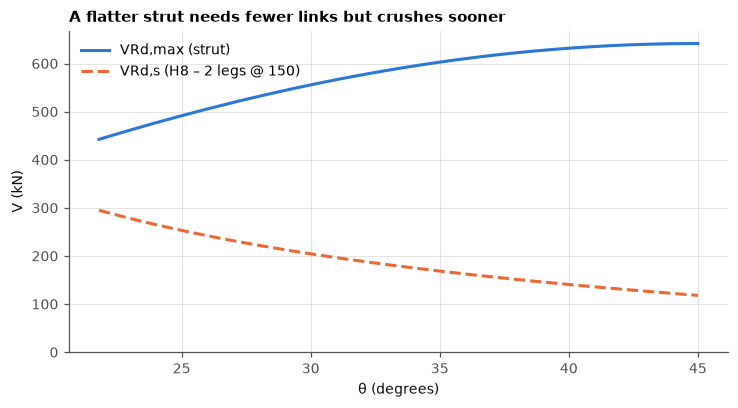

In [6]:
th = np.linspace(21.8, 45, 100)
bw, d, fck = V_["bw"], V_["d"], V_["fck"]
vmax = bw * .9 * d * .6 * (1 - fck / 250) * fck / 1.5 / (1 / np.tan(np.radians(th)) + np.tan(np.radians(th))) / 1e3
vs = V_["legs"] * D.area(V_["link"]) / V_["spacing"] * .9 * d * V_["fyk"] / 1.15 / np.tan(np.radians(th)) / 1e3
f, ax = plt.subplots(figsize=(6.6, 3.6))
ax.plot(th, vmax, color=P.BLUE, lw=2, label="VRd,max (strut)"); ax.plot(th, vs, color=P.ORANGE, lw=2, ls="--", label=f"VRd,s (H{V_['link']} – {V_['legs']} legs @ {V_['spacing']})")
ax.set_xlabel("θ (degrees)"); ax.set_ylabel("V (kN)"); ax.set_title("A flatter strut needs fewer links but crushes sooner"); ax.legend(); ax.set_ylim(0); plt.show()

## Punching shear (EC2 6.4)

- Column face: $v_{Ed,0} = \beta V_{Ed}/(u_0 d) \le v_{Rd,max}$ = 0.5νf<sub>cd</sub> (UK NA) or 0.4νf<sub>cd</sub> (EC2 recommended).
- Slabs: basic perimeter at 2d from the column.
- **Footings** (EC2 6.4.4(2)): *every* perimeter within 2d is checked, with the net upward soil pressure inside the perimeter deducted:

$$V_{Ed,red} = V_{Ed}-\Delta V_{Ed}, \qquad v_{Ed}=\frac{V_{Ed,red}}{ud}\left[1+k\frac{M_{Ed}u}{V_{Ed,red}W}\right], \qquad v_{Rd} = \max\{C_{Rd,c}k(100\rho f_{ck})^{1/3};\,v_{min}\}\frac{2d}{a}$$

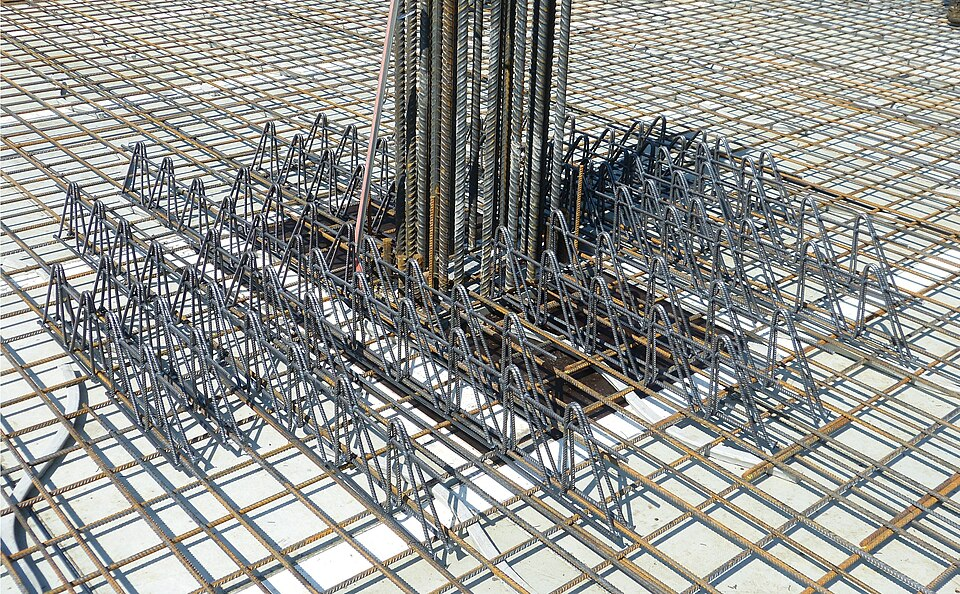

*Punching-shear reinforcement around a column in a flat slab. The pads in Section 6 are made deep enough not to need it.* <br><small>Photo: Get the picture, [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0), via [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Durchstanzbewehrung-Stahlbeton.jpg).</small>

In [7]:
photo("punching", "Punching-shear reinforcement around a column in a flat slab. The pads in Section 6 are made deep enough not to need it.")